In [105]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

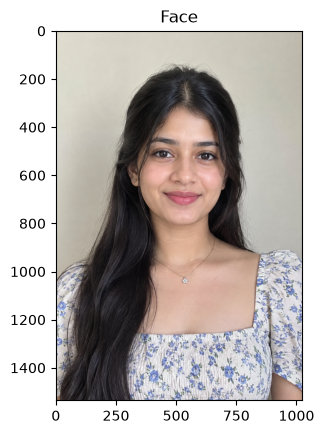

In [130]:
# Load the Face Image
faceImage = cv2.imread('08.png')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")

In [131]:
faceImage.shape

(1536, 1024, 3)

In [132]:
#resized_faceImage.shape
faceImage.shape

(1536, 1024, 3)

Text(0.5, 1.0, 'glassPNG')

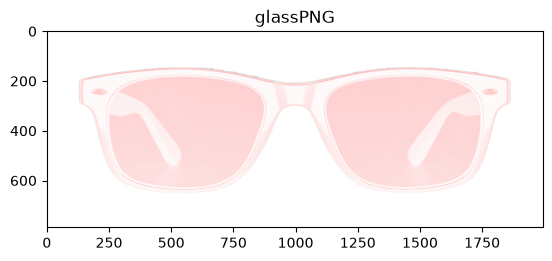

In [133]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [134]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(114,30))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(30, 114, 4)


In [135]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,:3]
glassMask = cv2.cvtColor(glassBGR,cv2.COLOR_BGR2GRAY)
glassMask = cv2.threshold(glassMask, 10, 225, cv2. THRESH_BINARY)[1]

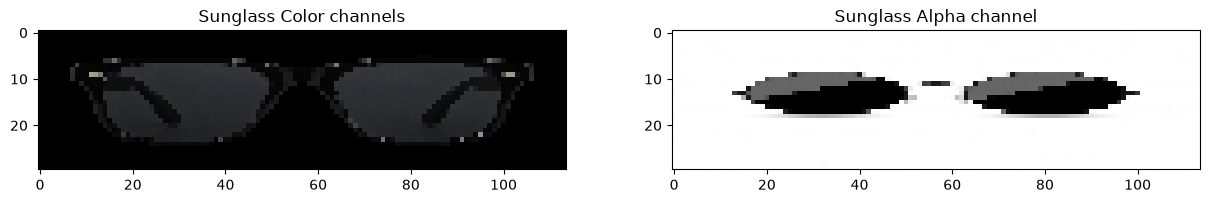

In [136]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

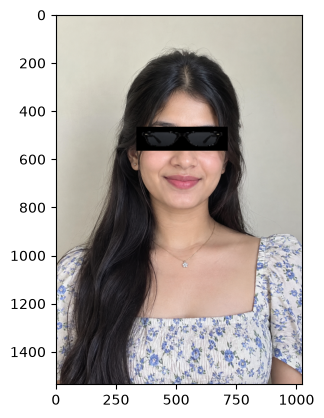

In [143]:
# Make a copy
#faceWithGlassesNaive = resized_faceImage.copy()
faceWithGlassesNaive = faceImage.copy()
glassResized = cv2.resize(glassBGR,(380, 100))

# Replace the eye region with the sunglass image
faceWithGlassesNaive[465:565 , 335:715]=glassResized

plt.imshow(faceWithGlassesNaive[...,::-1])

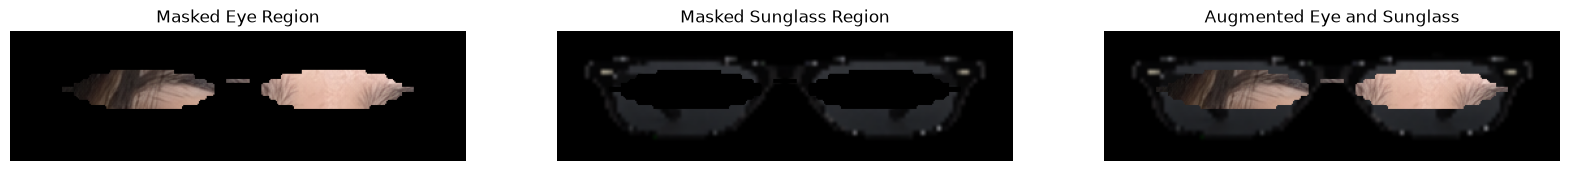

In [144]:
# Create 3-channel mask
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))
glassMask = (glassMask > 127).astype(np.uint8)

# Copy face image
faceWithGlassesArithmetic = faceImage.copy()

# Select girl's eye region (height=100, width=350)
eyeROI = faceWithGlassesArithmetic[420:520, 300:650]

# Resize glasses and mask to match eye region
glassResized = cv2.resize(glassBGR, (350, 100))
glassMask = cv2.resize(glassMask, (350, 100))

# Ensure mask has 3 channels
if glassMask.ndim == 2:
    glassMask = cv2.merge((glassMask, glassMask, glassMask))

# Create masked regions
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)
maskedGlass = cv2.multiply(glassResized, glassMask)

# Combine eye and glasses
eyeROIFinal = cv2.add(maskedEye, maskedGlass)

# Display 3 outputs
plt.figure(figsize=(20, 5))

plt.subplot(131)
plt.imshow(cv2.cvtColor(maskedEye, cv2.COLOR_BGR2RGB))
plt.title("Masked Eye Region")
plt.axis("off")

plt.subplot(132)
plt.imshow(cv2.cvtColor(maskedGlass, cv2.COLOR_BGR2RGB))
plt.title("Masked Sunglass Region")
plt.axis("off")

plt.subplot(133)
plt.imshow(cv2.cvtColor(eyeROIFinal, cv2.COLOR_BGR2RGB))
plt.title("Augmented Eye and Sunglass")
plt.axis("off")

plt.show()

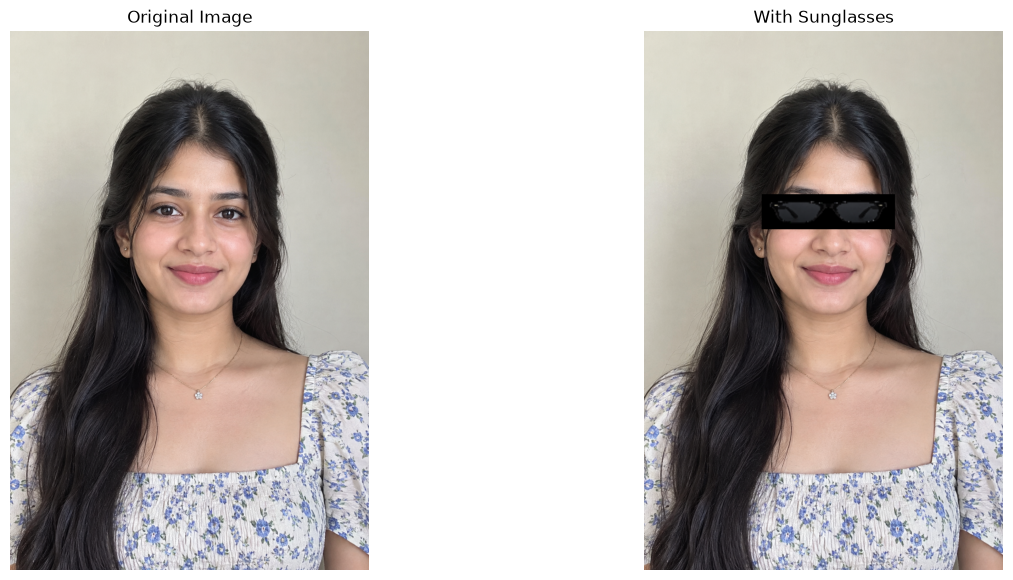

In [151]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()
glassResized = cv2.resize(glassBGR, (380, 100))

# Replace eye region with sunglasses
faceWithGlassesNaive[465:565, 335:715] = glassResized

# Display original and with sunglasses
plt.figure(figsize=(15, 7))

plt.subplot(121)
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(122)
plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.title("With Sunglasses")
plt.axis("off")

plt.show()